# 06 Feature Selection
Compare filter evidence, model importance, permutation importance, SHAP, and CV stability using development data only.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, roc_auc_score
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
from src.data_loader import load_raw_data
from src.feature_engineering import engineer_features
from src.preprocessing import prepare_catboost_frame

data = load_raw_data(PROJECT_ROOT / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv")
raw_features = data.drop(columns=["customerID", "Churn"])
features = engineer_features(raw_features)
target = data["Churn"].astype(int)
encoded_features = pd.get_dummies(features, dummy_na=True).fillna(0)
X_train, X_validation, y_train, y_validation = train_test_split(encoded_features, target, test_size=0.20, stratify=target, random_state=42)
print("Development rows:", len(X_train))
print("Validation rows:", len(X_validation))
print("Encoded feature count:", encoded_features.shape[1])

Development rows: 5634
Validation rows: 1409
Encoded feature count: 79


In [2]:
# Filter methods: missingness, near-zero variance, correlation, and mutual information.
missingness = features.isna().mean().rename("missing_fraction").to_frame()
missingness["missing_filter_flag"] = missingness["missing_fraction"] > 0.20
variance = encoded_features.var().rename("variance").to_frame().sort_values("variance")
low_variance = variance[variance["variance"] < 0.01].copy()
correlation = encoded_features.corr().abs()
upper_triangle = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
high_correlation_pairs = upper_triangle.stack().sort_values(ascending=False).head(20).rename("absolute_correlation").to_frame()
mi_scores = mutual_info_classif(X_train, y_train, random_state=42)
mi_table = pd.DataFrame({"feature": X_train.columns, "mutual_information": mi_scores}).sort_values("mutual_information", ascending=False)
print("Missingness candidates:")
display(missingness[missingness["missing_filter_flag"]])
print("Low-variance candidates:")
display(low_variance.head(20))
print("Highly correlated candidate pairs:")
display(high_correlation_pairs)
print("Top mutual-information features:")
display(mi_table.head(20))

Missingness candidates:


,missing_fraction,missing_filter_flag


Low-variance candidates:


,variance
Dependents_nan,0.0
gender_nan,0.0
Partner_nan,0.0
TechSupport_nan,0.0
InternetService_nan,0.0
OnlineSecurity_nan,0.0
MultipleLines_nan,0.0
PhoneService_nan,0.0
OnlineBackup_nan,0.0
DeviceProtection_nan,0.0


Highly correlated candidate pairs:


absolute_correlation
is_one_year_contract                 Contract_One year                                      1.0
InternetService_No                   StreamingMovies_No internet service                    1.0
is_two_year_contract                 Contract_Two year                                      1.0
OnlineSecurity_No internet service   TechSupport_No internet service                        1.0
                                     StreamingTV_No internet service                        1.0
InternetService_No                   StreamingTV_No internet service                        1.0
OnlineSecurity_No internet service   DeviceProtection_No internet service                   1.0
InternetService_No                   OnlineBackup_No internet service                       1.0
OnlineBackup_No internet service     StreamingTV_No internet service                        1.0
Dependents_No                        Dependents_Yes                                         1.0
number_of_support_services           TechSupport_Yes                                        1.0
DeviceProtection_No internet service StreamingMovies_No internet service                    1.0
                                     StreamingTV_No internet service                        1.0
OnlineBackup_No internet service     StreamingMovies_No internet service                    1.0
InternetService_No                   TechSupport_No internet service                        1.0
tenure                               tenure_years                                           1.0
                                     tenure_months                                          1.0
PhoneService_Yes                     MultipleLines_No phone service                         1.0
tenure_months                        tenure_years                                           1.0
PhoneService_No                      PhoneService_Yes                                       1.0

Top mutual-information features:


,feature,mutual_information
9,charge_per_tenure_month,0.132178
19,is_month_to_month,0.107363
67,Contract_Month-to-month,0.083055
4,tenure_months,0.076305
1,tenure,0.072306
5,tenure_years,0.070937
43,OnlineSecurity_No,0.065994
21,is_two_year_contract,0.059828
55,TechSupport_No,0.058590
2,MonthlyCharges,0.051675


Development ROC-AUC: 0.8460
Development PR-AUC: 0.6588


,feature,xgb_gain
67,Contract_Month-to-month,0.355555
19,is_month_to_month,0.196509
40,InternetService_Fiber optic,0.078787
9,charge_per_tenure_month,0.027447
43,OnlineSecurity_No,0.026399
55,TechSupport_No,0.026200
4,tenure_months,0.025788
72,PaperlessBilling_Yes,0.019610
76,PaymentMethod_Electronic check,0.016643
61,StreamingTV_Yes,0.011827


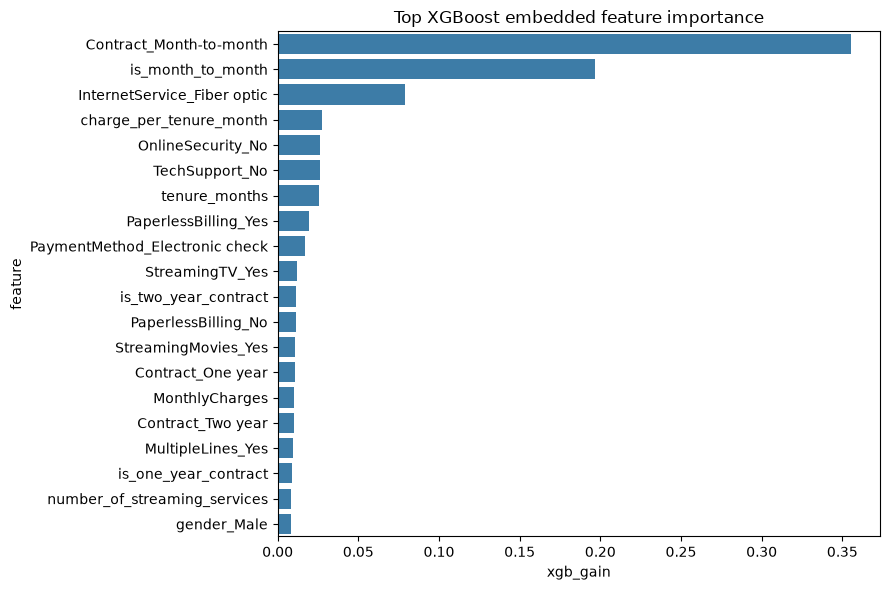

In [3]:
# Embedded XGBoost selection: gain importance is used as predictive-contribution evidence.
xgb_selector = XGBClassifier(n_estimators=120, max_depth=3, learning_rate=0.05, subsample=0.85, colsample_bytree=0.85, eval_metric="logloss", random_state=42, n_jobs=-1)
xgb_selector.fit(X_train, y_train)
xgb_gain = pd.DataFrame({"feature": X_train.columns, "xgb_gain": xgb_selector.feature_importances_}).sort_values("xgb_gain", ascending=False)
validation_probability = xgb_selector.predict_proba(X_validation)[:, 1]
print(f"Development ROC-AUC: {roc_auc_score(y_validation, validation_probability):.4f}")
print(f"Development PR-AUC: {average_precision_score(y_validation, validation_probability):.4f}")
display(xgb_gain.head(20))
plt.figure(figsize=(9, 6))
sns.barplot(data=xgb_gain.head(20), x="xgb_gain", y="feature", color="#2c7fb8")
plt.title("Top XGBoost embedded feature importance")
plt.tight_layout()
plt.show()

,feature,catboost_importance
34,is_month_to_month,19.314889
24,charge_per_tenure_month,9.454947
23,avg_monthly_charge,6.180833
17,MonthlyCharges,6.099475
8,OnlineSecurity,5.294681
36,is_two_year_contract,4.585430
20,tenure_years,4.330922
16,PaymentMethod,3.875979
28,number_of_streaming_services,3.693541
19,tenure_months,3.451738


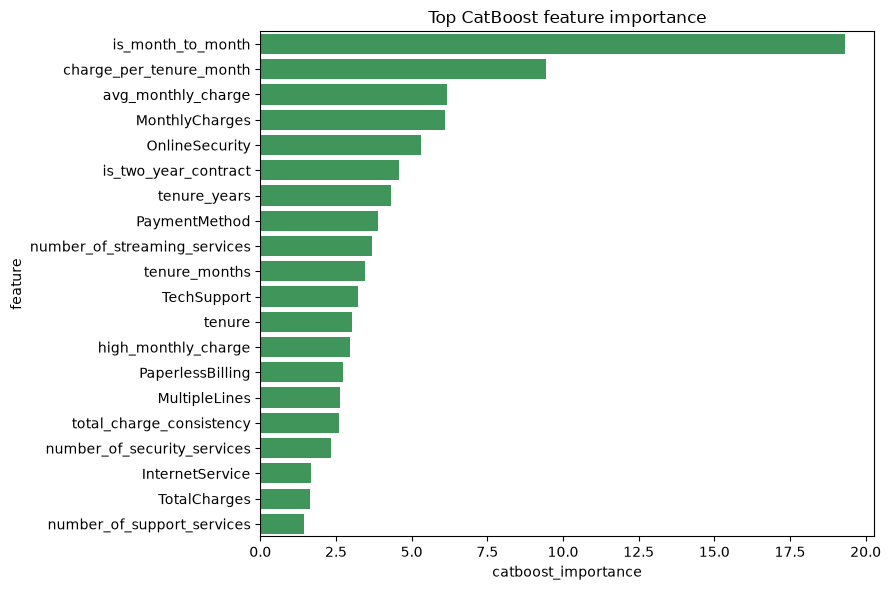

In [4]:
# Embedded CatBoost selection: native categorical columns are preserved for this diagnostic.
catboost_features, catboost_indices = prepare_catboost_frame(features)
cat_x_train, cat_x_validation, cat_y_train, cat_y_validation = train_test_split(catboost_features, target, test_size=0.20, stratify=target, random_state=42)
cat_selector = CatBoostClassifier(iterations=150, depth=5, learning_rate=0.05, loss_function="Logloss", eval_metric="AUC", verbose=False, random_seed=42, thread_count=-1, allow_writing_files=False)
cat_selector.fit(cat_x_train, cat_y_train, cat_features=catboost_indices)
catboost_importance = pd.DataFrame({"feature": catboost_features.columns, "catboost_importance": cat_selector.get_feature_importance()}).sort_values("catboost_importance", ascending=False)
display(catboost_importance.head(20))
plt.figure(figsize=(9, 6))
sns.barplot(data=catboost_importance.head(20), x="catboost_importance", y="feature", color="#31a354")
plt.title("Top CatBoost feature importance")
plt.tight_layout()
plt.show()

,feature,permutation_mean,permutation_std
9,charge_per_tenure_month,0.116058,0.005001
19,is_month_to_month,0.044961,0.003385
55,TechSupport_No,0.016317,0.003991
43,OnlineSecurity_No,0.009582,0.004580
3,TotalCharges,0.007168,0.001550
40,InternetService_Fiber optic,0.006452,0.008706
67,Contract_Month-to-month,0.003469,0.001679
76,PaymentMethod_Electronic check,0.003173,0.004934
21,is_two_year_contract,0.002911,0.003404
14,number_of_support_services,0.002710,0.001055


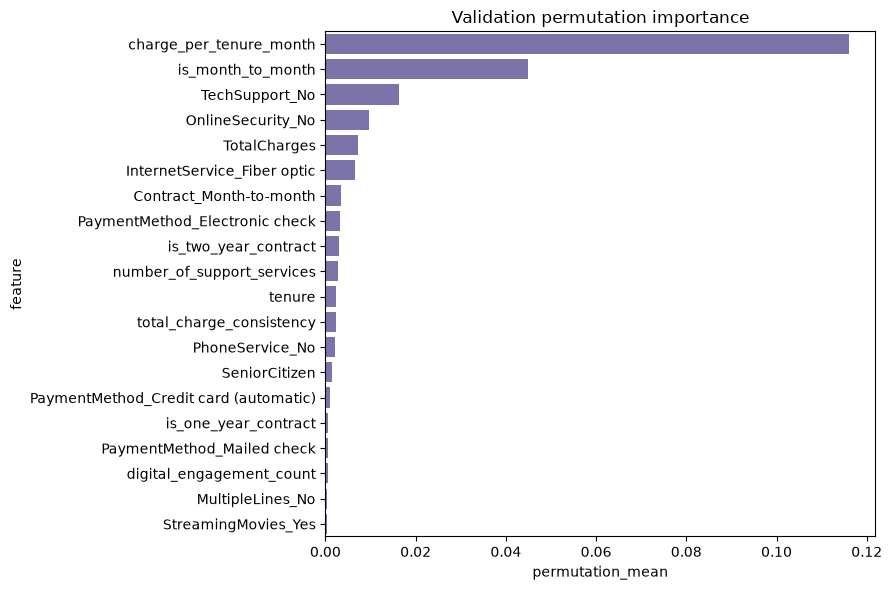

In [5]:
# Permutation selection uses validation data only; the final test set remains untouched.
permutation_result = permutation_importance(xgb_selector, X_validation, y_validation, scoring="average_precision", n_repeats=5, random_state=42, n_jobs=-1)
permutation_table = pd.DataFrame({"feature": X_validation.columns, "permutation_mean": permutation_result.importances_mean, "permutation_std": permutation_result.importances_std}).sort_values("permutation_mean", ascending=False)
display(permutation_table.head(20))
plt.figure(figsize=(9, 6))
sns.barplot(data=permutation_table.head(20), x="permutation_mean", y="feature", color="#756bb1")
plt.title("Validation permutation importance")
plt.tight_layout()
plt.show()

d:\Project\customer-churn\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,feature,mean_abs_shap
9,charge_per_tenure_month,0.496346
19,is_month_to_month,0.425982
43,OnlineSecurity_No,0.205694
55,TechSupport_No,0.183803
76,PaymentMethod_Electronic check,0.152065
40,InternetService_Fiber optic,0.148602
67,Contract_Month-to-month,0.141999
21,is_two_year_contract,0.112073
2,MonthlyCharges,0.102938
35,MultipleLines_No,0.095227


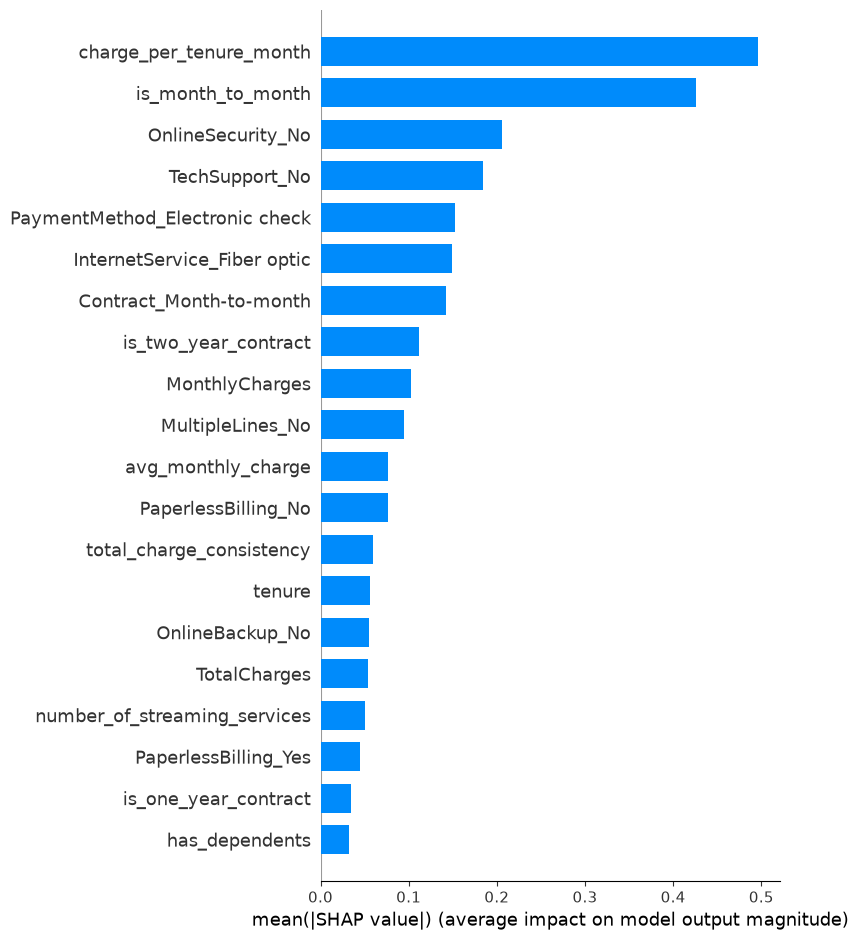

In [6]:
# SHAP is used as an interpretation and selection aid, not as an automatic deletion rule.
try:
    import shap
    shap_sample = X_validation.sample(min(500, len(X_validation)), random_state=42)
    shap_values = shap.TreeExplainer(xgb_selector)(shap_sample)
    shap_matrix = shap_values.values if hasattr(shap_values, "values") else shap_values
    shap_table = pd.DataFrame({"feature": shap_sample.columns, "mean_abs_shap": np.abs(shap_matrix).mean(axis=0)}).sort_values("mean_abs_shap", ascending=False)
    display(shap_table.head(20))
    shap.summary_plot(shap_matrix, shap_sample, plot_type="bar", show=False, max_display=20)
    plt.tight_layout()
    plt.show()
except Exception as error:
    shap_table = pd.DataFrame(columns=["feature", "mean_abs_shap"])
    print(f"SHAP diagnostic skipped: {type(error).__name__}: {error}")

,feature,selected_folds,selection_frequency
0,is_month_to_month,5,1.0
1,InternetService_Fiber optic,5,1.0
2,charge_per_tenure_month,5,1.0
3,OnlineSecurity_No,5,1.0
4,TechSupport_No,5,1.0
5,PaperlessBilling_No,5,1.0
6,PaymentMethod_Electronic check,5,1.0
7,StreamingMovies_Yes,5,1.0
8,is_two_year_contract,5,1.0
9,is_one_year_contract,5,1.0


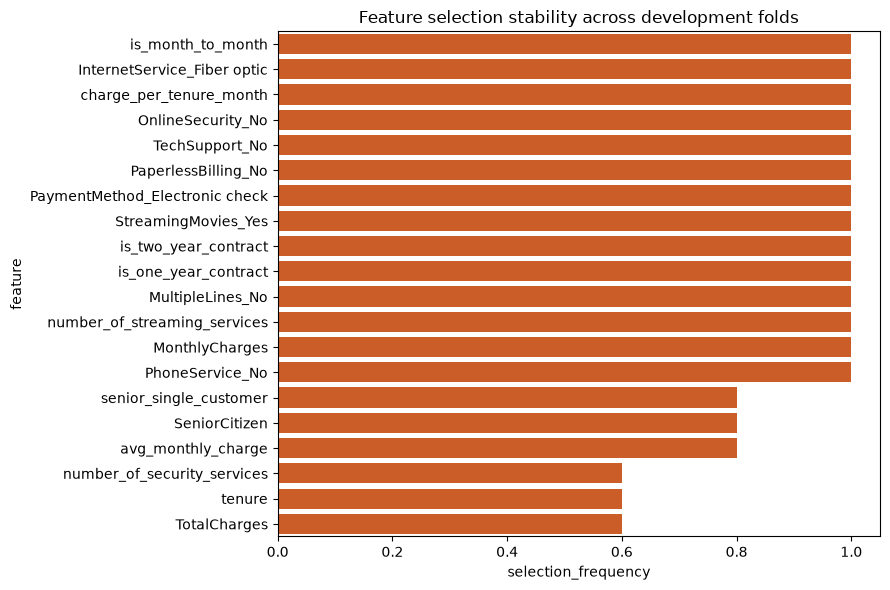

In [7]:
# Stability selection: repeat XGBoost rankings across five development folds.
fold_rankings = []
stability_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for fold, (train_indices, validation_indices) in enumerate(stability_cv.split(encoded_features, target), start=1):
    fold_model = XGBClassifier(n_estimators=80, max_depth=3, learning_rate=0.05, eval_metric="logloss", random_state=42 + fold, n_jobs=-1)
    fold_model.fit(encoded_features.iloc[train_indices], target.iloc[train_indices])
    fold_ranking = pd.DataFrame({"feature": encoded_features.columns, "importance": fold_model.feature_importances_}).sort_values("importance", ascending=False)
    fold_ranking["fold"] = fold
    fold_rankings.append(fold_ranking)
top_k = 20
selection_counts = pd.concat([ranking.head(top_k)[["feature"]] for ranking in fold_rankings]).value_counts().rename("selected_folds").to_frame()
selection_counts["selection_frequency"] = selection_counts["selected_folds"] / len(fold_rankings)
selection_stability = selection_counts.reset_index().sort_values(["selection_frequency", "selected_folds"], ascending=False)
display(selection_stability.head(30))
plt.figure(figsize=(9, 6))
sns.barplot(data=selection_stability.head(20), x="selection_frequency", y="feature", color="#e6550d")
plt.title("Feature selection stability across development folds")
plt.xlim(0, 1.05)
plt.tight_layout()
plt.show()

In [ ]:
# Combine evidence into a transparent candidate decision table.
top_mi = set(mi_table.head(20)["feature"])
top_xgb = set(xgb_gain.head(20)["feature"])
top_permutation = set(permutation_table.head(20)["feature"])
stable_features = set(selection_stability.loc[selection_stability["selection_frequency"] >= 0.60, "feature"])
shap_features = set(shap_table.head(20)["feature"]) if not shap_table.empty else set()
candidate_features = sorted(top_mi | top_xgb | top_permutation | stable_features | shap_features)
selection_decision = pd.DataFrame({"feature": candidate_features})
selection_decision["mi_evidence"] = selection_decision["feature"].isin(top_mi)
selection_decision["xgb_evidence"] = selection_decision["feature"].isin(top_xgb)
selection_decision["permutation_evidence"] = selection_decision["feature"].isin(top_permutation)
selection_decision["stable_in_cv"] = selection_decision["feature"].isin(stable_features)
selection_decision["shap_evidence"] = selection_decision["feature"].isin(shap_features)
evidence_columns = ["mi_evidence", "xgb_evidence", "permutation_evidence", "stable_in_cv", "shap_evidence"]
selection_decision["evidence_count"] = selection_decision[evidence_columns].sum(axis=1)
selection_decision["final_candidate"] = selection_decision["evidence_count"] >= 2
selection_decision = selection_decision.sort_values(["final_candidate", "evidence_count", "stable_in_cv"], ascending=[False, False, False])
display(selection_decision)
final_selected_features = selection_decision.loc[selection_decision["final_candidate"], "feature"].tolist()
print("The final_candidate flag is an evidence-based screening decision, not a guarantee that every candidate belongs in the final model.")
print(f"Candidate count: {len(final_selected_features)}")
print(final_selected_features)

,feature,mi_evidence,xgb_evidence,permutation_evidence,stable_in_cv,shap_evidence,evidence_count,final_candidate
4,InternetService_Fiber optic,True,True,True,True,True,5,True
10,OnlineSecurity_No,True,True,True,True,True,5,True
14,PaymentMethod_Electronic check,True,True,True,True,True,5,True
20,TechSupport_No,True,True,True,True,True,5,True
24,charge_per_tenure_month,True,True,True,True,True,5,True
29,is_month_to_month,True,True,True,True,True,5,True
32,is_two_year_contract,True,True,True,True,True,5,True
6,MonthlyCharges,True,True,False,True,True,4,True
22,TotalCharges,True,False,True,True,True,4,True
31,is_one_year_contract,False,True,True,True,True,4,True


Final candidate features are evidence-based and must still be compared against the raw and engineered feature sets in model validation.
Candidate count: 24
['InternetService_Fiber optic', 'OnlineSecurity_No', 'PaymentMethod_Electronic check', 'TechSupport_No', 'charge_per_tenure_month', 'is_month_to_month', 'is_two_year_contract', 'MonthlyCharges', 'TotalCharges', 'is_one_year_contract', 'tenure', 'Contract_Month-to-month', 'MultipleLines_No', 'PaperlessBilling_No', 'StreamingMovies_Yes', 'avg_monthly_charge', 'number_of_streaming_services', 'PhoneService_No', 'SeniorCitizen', 'has_dependents', 'Contract_Two year', 'PaperlessBilling_Yes', 'tenure_months', 'total_charge_consistency']


## Feature-set decision rules

- Feature Set A: raw predictors, used as the baseline representation.
- Feature Set B: raw predictors plus the engineered features from notebook 05.
- Feature Set C: filter-supported features from missingness, variance, correlation, statistical evidence, and MI.
- Feature Set D: embedded, permutation, SHAP, and stability-supported features.
- Feature Set E: the final optimized set, selected only after comparing validation performance, stability, interpretability, and business relevance.

The `final_candidate` flag above is a reproducible screening decision, not a claim that every candidate must be used in the final model. The untouched test set must not be used for this selection step.

## Validation comparison of feature sets
The final feature set must be selected using development validation evidence rather than importance alone. This cell compares raw, engineered, and screened feature representations using the allowed XGBoost model family. The untouched test set is not used.


In [9]:
raw_encoded = pd.get_dummies(raw_features, dummy_na=True).fillna(0)
raw_train = raw_encoded.loc[X_train.index]
raw_validation = raw_encoded.loc[X_validation.index]
feature_sets = {
    "Raw": (raw_train, raw_validation, raw_encoded.columns.tolist()),
    "Engineered": (X_train, X_validation, encoded_features.columns.tolist()),
    "Evidence-selected": (X_train, X_validation, [feature for feature in final_selected_features if feature in encoded_features.columns]),
}
feature_set_rows = []
for feature_set_name, (train_matrix, validation_matrix, columns) in feature_sets.items():
    model = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.05, subsample=0.85, colsample_bytree=0.85, eval_metric="logloss", random_state=42, n_jobs=-1)
    model.fit(train_matrix[columns], y_train)
    probabilities = model.predict_proba(validation_matrix[columns])[:, 1]
    feature_set_rows.append({"feature_set": feature_set_name, "feature_count": len(columns), "roc_auc": roc_auc_score(y_validation, probabilities), "pr_auc": average_precision_score(y_validation, probabilities)})
feature_set_comparison = pd.DataFrame(feature_set_rows).sort_values("pr_auc", ascending=False)
display(feature_set_comparison)
best_feature_set = feature_set_comparison.iloc[0]["feature_set"]
print(f"Best development feature set by PR-AUC: {best_feature_set}")

,feature_set,feature_count,roc_auc,pr_auc
0,Raw,60,0.846990,0.660866
1,Engineered,79,0.846589,0.660475
2,Evidence-selected,24,0.846581,0.656138


Best development feature set by PR-AUC: Raw


In [10]:
feature_reason_map = {
    "tenure": "Strong and stable lifecycle signal; retain as the primary tenure representation.",
    "MonthlyCharges": "Provides complementary price exposure information.",
    "TotalCharges": "Captures accumulated billing history; impute missing values inside the model pipeline.",
    "Contract": "Strong categorical churn association and business interpretability.",
    "InternetService": "Captures service-type differences and nonlinear churn patterns.",
    "TechSupport": "Strong service/support association and actionable business meaning.",
    "PaymentMethod": "Shows meaningful churn segmentation and operational relevance.",
    "OnlineSecurity": "Captures protection-service adoption and service engagement.",
    "OnlineBackup": "Captures additional service adoption; retain only if validation/stability supports it.",
    "DeviceProtection": "Captures protection-service adoption; compare against aggregate service counts.",
    "StreamingTV": "Potential engagement signal; lower priority if redundant with streaming aggregates.",
    "StreamingMovies": "Potential engagement signal; lower priority if redundant with streaming aggregates.",
    "SeniorCitizen": "Important customer-profile segment indicator.",
    "Partner": "Household-profile association with interpretable business meaning.",
    "Dependents": "Household-profile association and retention-segmentation value.",
    "tenure_months": "Engineered alias for tenure; use only if it improves validation or reporting clarity.",
    "is_new_customer": "Business threshold feature for onboarding risk; validate threshold on development data.",
    "is_month_to_month": "Actionable contract indicator; compare against native Contract to avoid duplication.",
    "number_of_services": "Compact service-breadth summary; compare against individual service columns.",
    "digital_engagement_count": "Compact digital-engagement summary; retain only if stable and useful beyond components.",
}
recommended_rows = []
for feature in final_selected_features:
    reason = feature_reason_map.get(feature, "Selected because it met at least two development-only evidence criteria; review its encoded category and redundancy before final training.")
    recommended_rows.append({"selected_feature": feature, "reason": reason, "selection_rule": "At least two of MI, XGBoost, permutation, SHAP, or CV-stability evidence"})
recommended_features_table = pd.DataFrame(recommended_rows)
display(recommended_features_table)
print("Important: this is the development recommendation. Final model features must be locked before untouched test evaluation.")

,selected_feature,reason,selection_rule
0,InternetService_Fiber optic,Selected because it met at least two developme...,"At least two of MI, XGBoost, permutation, SHAP..."
1,OnlineSecurity_No,Selected because it met at least two developme...,"At least two of MI, XGBoost, permutation, SHAP..."
2,PaymentMethod_Electronic check,Selected because it met at least two developme...,"At least two of MI, XGBoost, permutation, SHAP..."
3,TechSupport_No,Selected because it met at least two developme...,"At least two of MI, XGBoost, permutation, SHAP..."
4,charge_per_tenure_month,Selected because it met at least two developme...,"At least two of MI, XGBoost, permutation, SHAP..."
5,is_month_to_month,Actionable contract indicator; compare against...,"At least two of MI, XGBoost, permutation, SHAP..."
6,is_two_year_contract,Selected because it met at least two developme...,"At least two of MI, XGBoost, permutation, SHAP..."
7,MonthlyCharges,Provides complementary price exposure informat...,"At least two of MI, XGBoost, permutation, SHAP..."
8,TotalCharges,Captures accumulated billing history; impute m...,"At least two of MI, XGBoost, permutation, SHAP..."
9,is_one_year_contract,Selected because it met at least two developme...,"At least two of MI, XGBoost, permutation, SHAP..."


Important: this is the development recommendation. Final model features must be locked before untouched test evaluation.


In [11]:
print("Best representation by development PR-AUC:", best_feature_set)
print("Raw representation should be the primary baseline for model building because it performed best in this comparison.")
print("The evidence-selected set remains a compact experiment, not the default final set.")
print("Screened feature columns:")
for feature in final_selected_features:
    print("-", feature)
print("Before final test evaluation, lock the representation and feature list using validation evidence only.")

Best representation by development PR-AUC: Raw
Raw representation should be the primary baseline for model building because it performed best in this comparison.
The evidence-selected set remains a compact experiment, not the default final set.
Screened feature columns:
- InternetService_Fiber optic
- OnlineSecurity_No
- PaymentMethod_Electronic check
- TechSupport_No
- charge_per_tenure_month
- is_month_to_month
- is_two_year_contract
- MonthlyCharges
- TotalCharges
- is_one_year_contract
- tenure
- Contract_Month-to-month
- MultipleLines_No
- PaperlessBilling_No
- StreamingMovies_Yes
- avg_monthly_charge
- number_of_streaming_services
- PhoneService_No
- SeniorCitizen
- has_dependents
- Contract_Two year
- PaperlessBilling_Yes
- tenure_months
- total_charge_consistency
Before final test evaluation, lock the representation and feature list using validation evidence only.
